## multinomial naive bayes


In [1]:
import numpy as np

# Document-term matrix
# Columns: free, prize, win, project, meeting, work

X = np.array([
    [2, 1, 0, 0, 0, 0],  # Spam
    [1, 1, 1, 0, 0, 0],  # Spam
    [0, 0, 0, 1, 1, 0],  # Not Spam
    [0, 0, 0, 1, 1, 1]   # Not Spam
])

# 1 = Spam, 0 = Not Spam
y = np.array([1, 1, 0, 0])

vocabulary = [
    "free",
    "prize",
    "win",
    "project",
    "meeting",
    "work"
]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4, 6)
y shape: (4,)


In [2]:
import pandas as pd

df = pd.DataFrame(X, columns=vocabulary)
df["class"] = y

df

,free,prize,win,project,meeting,work,class
0,2,1,0,0,0,0,1
1,1,1,1,0,0,0,1
2,0,0,0,1,1,0,0
3,0,0,0,1,1,1,0


In [3]:
class MultinomialNB:
    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        if np.any(X < 0):
            raise ValueError("Feature counts cannot be negative.")

        if self.alpha <= 0:
            raise ValueError("Alpha must be positive.")

        self.classes_ = np.unique(y)

        n_samples, n_features = X.shape
        n_classes = len(self.classes_)

        # Store class statistics
        self.class_prior_ = np.zeros(n_classes)

        self.feature_count_ = np.zeros(
            (n_classes, n_features)
        )

        # Calculate statistics for each class
        for index, class_label in enumerate(self.classes_):

            X_class = X[y == class_label]

            # Prior probability
            self.class_prior_[index] = (
                len(X_class) / n_samples
            )

            # Total word counts for this class
            self.feature_count_[index] = np.sum(
                X_class,
                axis=0
            )

        # Apply Laplace smoothing
        smoothed_counts = self.feature_count_ + self.alpha

        smoothed_totals = (
            np.sum(self.feature_count_, axis=1, keepdims=True)
            + self.alpha * n_features
        )

        # Calculate log likelihoods
        self.feature_log_prob_ = np.log(
            smoothed_counts / smoothed_totals
        )

        return self

    def predict_log_proba(self, X):
        X = np.asarray(X, dtype=float)

        if np.any(X < 0):
            raise ValueError("Feature counts cannot be negative.")

        # Calculate log prior
        log_prior = np.log(self.class_prior_)

        # Calculate class log scores
        log_scores = (
            X @ self.feature_log_prob_.T
            + log_prior
        )

        return log_scores

    def predict(self, X):
        log_scores = self.predict_log_proba(X)

        predicted_indices = np.argmax(
            log_scores,
            axis=1
        )

        return self.classes_[predicted_indices]

    def predict_proba(self, X):
        log_scores = self.predict_log_proba(X)

        shifted_scores = (
            log_scores
            - np.max(log_scores, axis=1, keepdims=True)
        )

        exp_scores = np.exp(shifted_scores)

        return exp_scores / np.sum(
            exp_scores,
            axis=1,
            keepdims=True
        )

In [5]:
model = MultinomialNB(alpha=1.0)

model.fit(X, y)

print("Classes:", model.classes_)

print("\nClass priors:")
print(model.class_prior_)

print("\nWord counts per class:")
print(model.feature_count_)

print("\nWord log probabilities:")
print(model.feature_log_prob_)

Classes: [0 1]

Class priors:
[0.5 0.5]

Word counts per class:
[[0. 0. 0. 2. 2. 1.]
 [3. 2. 1. 0. 0. 0.]]

Word log probabilities:
[[-2.39789527 -2.39789527 -2.39789527 -1.29928298 -1.29928298 -1.70474809]
 [-1.09861229 -1.38629436 -1.79175947 -2.48490665 -2.48490665 -2.48490665]]


In [6]:
# free=1, prize=1, all other words=0
new_email = np.array([
    [1, 1, 0, 0, 0, 0]
])

prediction = model.predict(new_email)

probabilities = model.predict_proba(new_email)

print("Predicted class:", prediction[0])
print("Class order:", model.classes_)
print("Probabilities:", probabilities)

Predicted class: 1
Class order: [0 1]
Probabilities: [[0.09022556 0.90977444]]


In [7]:
for index, class_label in enumerate(model.classes_):
    print(
        f"Class {class_label}: "
        f"{probabilities[0][index]:.4f}"
    )

Class 0: 0.0902
Class 1: 0.9098


## scikit learn implementation

In [8]:
from sklearn.naive_bayes import MultinomialNB as SklearnMultinomialNB

sklearn_model = SklearnMultinomialNB(alpha=1.0)

sklearn_model.fit(X, y)

sklearn_prediction = sklearn_model.predict(new_email)

sklearn_probabilities = sklearn_model.predict_proba(new_email)

print("Scratch prediction:", prediction)
print("Sklearn prediction:", sklearn_prediction)

print("\nScratch probabilities:", probabilities)
print("Sklearn probabilities:", sklearn_probabilities)

print(
    "\nPredictions identical:",
    np.array_equal(prediction, sklearn_prediction)
)

print(
    "Probabilities match:",
    np.allclose(probabilities, sklearn_probabilities)
)

Scratch prediction: [1]
Sklearn prediction: [1]

Scratch probabilities: [[0.09022556 0.90977444]]
Sklearn probabilities: [[0.09022556 0.90977444]]

Predictions identical: True
Probabilities match: True


In [9]:
from sklearn.feature_extraction.text import CountVectorizer

emails = [
    "free prize free",
    "free money prize",
    "win free prize",
    "meeting tomorrow",
    "project meeting tomorrow",
    "schedule the meeting"
]

vectorizer = CountVectorizer()

X_text = vectorizer.fit_transform(emails)

print("Vocabulary:")
print(vectorizer.get_feature_names_out())

print("\nDocument-term matrix:")
print(X_text.toarray())

Vocabulary:
['free' 'meeting' 'money' 'prize' 'project' 'schedule' 'the' 'tomorrow'
 'win']

Document-term matrix:
[[2 0 0 1 0 0 0 0 0]
 [1 0 1 1 0 0 0 0 0]
 [1 0 0 1 0 0 0 0 1]
 [0 1 0 0 0 0 0 1 0]
 [0 1 0 0 1 0 0 1 0]
 [0 1 0 0 0 1 1 0 0]]


In [10]:
labels = np.array([1, 1, 1, 0, 0, 0])

text_model = SklearnMultinomialNB(alpha=1.0)

text_model.fit(X_text, labels)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[3.,3.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.69,-0.69]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 9)","[[0.,3.,0.,...,1.,2.,0.], [4.,0.,1.,...,0.,0.,1.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 9)","[[-2.83,-1.45,-2.83,...,-2.14,-1.73,-2.83], [-1.28,-2.89,-2.2 ,...,-2.89,-2.89,-2.2 ]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9


In [11]:
new_emails = [
    "free prize",
    "meeting tomorrow",
    "free money winner",
    "project schedule"
]

new_email_features = vectorizer.transform(new_emails)

predictions = text_model.predict(new_email_features)

probabilities = text_model.predict_proba(new_email_features)

for i, email in enumerate(new_emails):
    print("\nEmail:", email)
    print(
        "Prediction:",
        "Spam" if predictions[i] == 1 else "Not Spam"
    )
    print("Probabilities:", probabilities[i])


Email: free prize
Prediction: Spam
Probabilities: [0.05307995 0.94692005]

Email: meeting tomorrow
Prediction: Not Spam
Probabilities: [0.93081159 0.06918841]

Email: free money winner
Prediction: Spam
Probabilities: [0.10080896 0.89919104]

Email: project schedule
Prediction: Not Spam
Probabilities: [0.81766562 0.18233438]


## REAL DATASET

In [15]:
from pathlib import Path
import urllib.request
import zipfile

# Dataset location
data_dir = Path("../data/sms_spam")
data_dir.mkdir(parents=True, exist_ok=True)

zip_path = data_dir / "sms_spam_collection.zip"
extract_dir = data_dir / "extracted"

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

# Download
if not zip_path.exists():
    urllib.request.urlretrieve(url, zip_path)
    print("Dataset downloaded.")

# Extract
extract_dir.mkdir(exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

print("Dataset extracted.")

Dataset downloaded.
Dataset extracted.


In [16]:
import pandas as pd

file_path = extract_dir / "SMSSpamCollection"

df = pd.read_csv(
    file_path,
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [17]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["label"].value_counts())

Dataset shape: (5572, 2)

Missing values:
label      0
message    0
dtype: int64

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


In [18]:
messages = df["message"].astype(str)

labels = df["label"].map({
    "ham": 0,
    "spam": 1
})

print("Messages:", len(messages))
print("Labels:", len(labels))

Messages: 5572
Labels: 5572


In [19]:
from sklearn.model_selection import train_test_split

X = df["message"].astype(str)

y = df["label"].map({
    "ham": 0,
    "spam": 1
})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training samples: 4457
Testing samples: 1115

Training distribution:
label
0    3859
1     598
Name: count, dtype: int64

Testing distribution:
label
0    966
1    149
Name: count, dtype: int64


In [20]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

sms_pipeline = Pipeline([
    ("vectorizer", CountVectorizer()),
    ("classifier", MultinomialNB(alpha=1.0))
])

In [21]:
sms_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('vectorizer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True


In [22]:
y_pred = sms_pipeline.predict(X_test)

In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))

print("Recall:", recall_score(y_test, y_pred))

print("F1 Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"]
))

Accuracy: 0.9874439461883409
Precision: 0.9856115107913669
Recall: 0.9194630872483222
F1 Score: 0.9513888888888888

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       966
        Spam       0.99      0.92      0.95       149

    accuracy                           0.99      1115
   macro avg       0.99      0.96      0.97      1115
weighted avg       0.99      0.99      0.99      1115



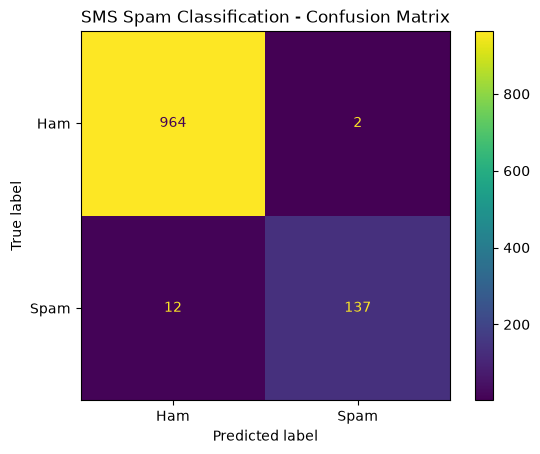

In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Ham", "Spam"]
)

plt.title("SMS Spam Classification - Confusion Matrix")
plt.show()

In [25]:
majority_class_accuracy = (y_test == 0).mean()

print(
    "Majority-class baseline accuracy:",
    majority_class_accuracy
)

print(
    "Multinomial NB accuracy:",
    accuracy_score(y_test, y_pred)
)

Majority-class baseline accuracy: 0.8663677130044843
Multinomial NB accuracy: 0.9874439461883409


In [26]:
results = pd.DataFrame({
    "message": X_test.values,
    "actual": y_test.values,
    "predicted": y_pred
})

misclassified = results[
    results["actual"] != results["predicted"]
]

print("Total misclassified:", len(misclassified))

misclassified.head(15)

Total misclassified: 14


,message,actual,predicted
44,FreeMsg Hey there darling it's been 3 week's n...,1,0
219,Sorry I missed your call let's talk when you h...,1,0
235,"Latest News! Police station toilet stolen, cop...",1,0
418,Can U get 2 phone NOW? I wanna chat 2 set up m...,1,0
433,"Hi babe its Jordan, how r u? Im home from abro...",1,0
467,More people are dogging in your area now. Call...,1,0
478,For sale - arsenal dartboard. Good condition b...,1,0
491,Can u get pic msgs to your phone?,0,1
606,Email AlertFrom: Jeri StewartSize: 2KBSubject:...,1,0
700,We have sent JD for Customer Service cum Accou...,0,1


In [27]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

alpha_values = [0.01, 0.1, 0.5, 1.0, 2.0, 5.0]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

alpha_results = []

for alpha in alpha_values:

    pipeline = Pipeline([
        ("vectorizer", CountVectorizer()),
        ("classifier", MultinomialNB(alpha=alpha))
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="f1"
    )

    alpha_results.append({
        "alpha": alpha,
        "mean_f1": scores.mean(),
        "std_f1": scores.std()
    })

alpha_df = pd.DataFrame(alpha_results)

alpha_df

,alpha,mean_f1,std_f1
0,0.01,0.944351,0.017160
1,0.10,0.948779,0.015670
2,0.50,0.948447,0.010840
3,1.00,0.947777,0.011090
4,2.00,0.933119,0.010724
5,5.00,0.884563,0.015548


In [28]:
pd.set_option("display.max_colwidth", None)

misclassified[
    ["message", "actual", "predicted"]
]

,message,actual,predicted
44,"FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv",1,0
219,Sorry I missed your call let's talk when you have the time. I'm on 07090201529,1,0
235,"Latest News! Police station toilet stolen, cops have nothing to go on!",1,0
418,Can U get 2 phone NOW? I wanna chat 2 set up meet Call me NOW on 09096102316 U can cum here 2moro Luv JANE xx Calls£1/minmoremobsEMSPOBox45PO139WA,1,0
433,"Hi babe its Jordan, how r u? Im home from abroad and lonely, text me back if u wanna chat xxSP visionsms.com Text stop to stopCost 150p 08712400603",1,0
467,More people are dogging in your area now. Call 09090204448 and join like minded guys. Why not arrange 1 yourself. There's 1 this evening. A£1.50 minAPN LS278BB,1,0
478,For sale - arsenal dartboard. Good condition but no doubles or trebles!,1,0
491,Can u get pic msgs to your phone?,0,1
606,Email AlertFrom: Jeri StewartSize: 2KBSubject: Low-cost prescripiton drvgsTo listen to email call 123,1,0
700,"We have sent JD for Customer Service cum Accounts Executive to ur mail id, For details contact us",0,1


In [29]:
false_negatives = misclassified[
    (misclassified["actual"] == 1) &
    (misclassified["predicted"] == 0)
]

false_positives = misclassified[
    (misclassified["actual"] == 0) &
    (misclassified["predicted"] == 1)
]

print("False negatives:", len(false_negatives))
print("False positives:", len(false_positives))

False negatives: 12
False positives: 2


In [30]:
MultinomialNB(alpha=1.0)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None


In [31]:
alpha_df.sort_values(
    by="mean_f1",
    ascending=False
)

,alpha,mean_f1,std_f1
1,0.10,0.948779,0.015670
2,0.50,0.948447,0.010840
3,1.00,0.947777,0.011090
0,0.01,0.944351,0.017160
4,2.00,0.933119,0.010724
5,5.00,0.884563,0.015548


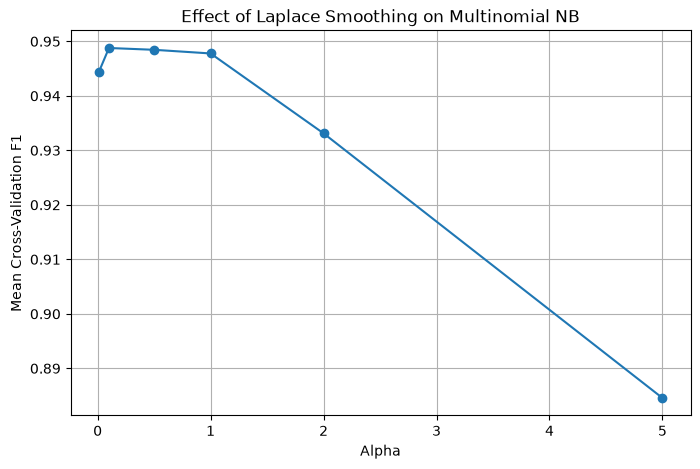

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(
    alpha_df["alpha"],
    alpha_df["mean_f1"],
    marker="o"
)

plt.xlabel("Alpha")
plt.ylabel("Mean Cross-Validation F1")
plt.title("Effect of Laplace Smoothing on Multinomial NB")
plt.grid(True)

plt.show()

In [33]:
best_alpha = 0.1

best_sms_pipeline = Pipeline([
    ("vectorizer", CountVectorizer()),
    ("classifier", MultinomialNB(alpha=best_alpha))
])

best_sms_pipeline.fit(X_train, y_train)

print("Selected alpha:", best_alpha)

Selected alpha: 0.1


In [34]:
y_pred_best = best_sms_pipeline.predict(X_test)

print("Accuracy:",
      accuracy_score(y_test, y_pred_best))

print("Precision:",
      precision_score(y_test, y_pred_best))

print("Recall:",
      recall_score(y_test, y_pred_best))

print("F1:",
      f1_score(y_test, y_pred_best))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_best,
    target_names=["Ham", "Spam"]
))

Accuracy: 0.9883408071748879
Precision: 0.9788732394366197
Recall: 0.9328859060402684
F1: 0.9553264604810997

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       966
        Spam       0.98      0.93      0.96       149

    accuracy                           0.99      1115
   macro avg       0.98      0.96      0.97      1115
weighted avg       0.99      0.99      0.99      1115



In [35]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1"],
    "Alpha 1.0": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ],
    "Alpha 0.1": [
        accuracy_score(y_test, y_pred_best),
        precision_score(y_test, y_pred_best),
        recall_score(y_test, y_pred_best),
        f1_score(y_test, y_pred_best)
    ]
})

comparison

,Metric,Alpha 1.0,Alpha 0.1
0,Accuracy,0.987444,0.988341
1,Precision,0.985612,0.978873
2,Recall,0.919463,0.932886
3,F1,0.951389,0.955326


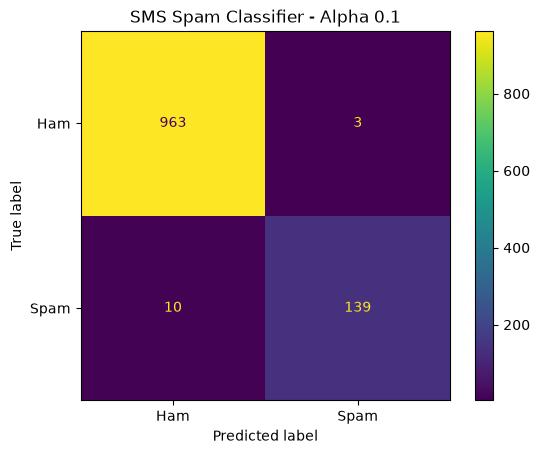

In [36]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    display_labels=["Ham", "Spam"]
)

plt.title("SMS Spam Classifier - Alpha 0.1")
plt.show()

In [37]:
new_messages = [
    "Congratulations! You have won a free cash prize. Claim now!",
    "Hey, are we still meeting tomorrow?",
    "URGENT! Your account has been selected for a cash reward.",
    "Can you please send me the assignment?",
    "WINNER! Call this number now to claim your free gift."
]

predictions = best_sms_pipeline.predict(new_messages)

probabilities = best_sms_pipeline.predict_proba(new_messages)

for i, message in enumerate(new_messages):

    predicted_class = predictions[i]

    print("\nMessage:", message)

    print(
        "Prediction:",
        "SPAM" if predicted_class == 1 else "HAM"
    )

    print(f"Ham probability: {probabilities[i][0]:.4f}")
    print(f"Spam probability: {probabilities[i][1]:.4f}")


Message: Congratulations! You have won a free cash prize. Claim now!
Prediction: SPAM
Ham probability: 0.0000
Spam probability: 1.0000

Message: Hey, are we still meeting tomorrow?
Prediction: HAM
Ham probability: 1.0000
Spam probability: 0.0000

Message: URGENT! Your account has been selected for a cash reward.
Prediction: SPAM
Ham probability: 0.0000
Spam probability: 1.0000

Message: Can you please send me the assignment?
Prediction: HAM
Ham probability: 0.9913
Spam probability: 0.0087

Message: WINNER! Call this number now to claim your free gift.
Prediction: SPAM
Ham probability: 0.0000
Spam probability: 1.0000


In [38]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_pipeline = Pipeline([
    ("vectorizer", TfidfVectorizer()),
    ("classifier", MultinomialNB(alpha=0.1))
])

tfidf_pipeline.fit(X_train, y_train)

tfidf_predictions = tfidf_pipeline.predict(X_test)

In [39]:
tfidf_results = {
    "Accuracy": accuracy_score(y_test, tfidf_predictions),
    "Precision": precision_score(y_test, tfidf_predictions),
    "Recall": recall_score(y_test, tfidf_predictions),
    "F1": f1_score(y_test, tfidf_predictions)
}

count_results = {
    "Accuracy": accuracy_score(y_test, y_pred_best),
    "Precision": precision_score(y_test, y_pred_best),
    "Recall": recall_score(y_test, y_pred_best),
    "F1": f1_score(y_test, y_pred_best)
}

feature_comparison = pd.DataFrame({
    "CountVectorizer": count_results,
    "TF-IDF": tfidf_results
})

feature_comparison

,CountVectorizer,TF-IDF
Accuracy,0.988341,0.984753
Precision,0.978873,1.000000
Recall,0.932886,0.885906
F1,0.955326,0.939502


In [40]:
ngram_results = []

for ngram_range in [(1, 1), (1, 2), (1, 3)]:

    pipeline = Pipeline([
        (
            "vectorizer",
            CountVectorizer(ngram_range=ngram_range)
        ),
        (
            "classifier",
            MultinomialNB(alpha=0.1)
        )
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    ngram_results.append({
        "ngram_range": str(ngram_range),
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions),
        "recall": recall_score(y_test, predictions),
        "f1": f1_score(y_test, predictions),
        "vocabulary_size": len(
            pipeline.named_steps["vectorizer"].vocabulary_
        )
    })

ngram_df = pd.DataFrame(ngram_results)

ngram_df

,ngram_range,accuracy,precision,recall,f1,vocabulary_size
0,"(1, 1)",0.988341,0.978873,0.932886,0.955326,7668
1,"(1, 2)",0.989238,0.979021,0.939597,0.958904,42696
2,"(1, 3)",0.985650,0.958621,0.932886,0.945578,87201


In [41]:
bigram_pipeline = Pipeline([
    (
        "vectorizer",
        CountVectorizer(ngram_range=(1, 2))
    ),
    (
        "classifier",
        MultinomialNB(alpha=0.1)
    )
])

bigram_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('vectorizer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentword n-grams or char n-grams to be extracted. All values of n suchsuch that min_n <= n <= max_n will be used. For example an``ngram_range`` of ``(1, 1)`` means only unigrams, ``(1, 2)`` meansunigrams and bigrams, and ``(2, 2)`` means only bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None


In [42]:
vectorizer = bigram_pipeline.named_steps["vectorizer"]
classifier = bigram_pipeline.named_steps["classifier"]

feature_names = vectorizer.get_feature_names_out()

# Class order: 0 = Ham, 1 = Spam
spam_log_probs = classifier.feature_log_prob_[1]
ham_log_probs = classifier.feature_log_prob_[0]

# Difference between spam and ham log probabilities
spam_association = spam_log_probs - ham_log_probs

top_spam_indices = np.argsort(spam_association)[-20:][::-1]

top_spam_words = pd.DataFrame({
    "feature": feature_names[top_spam_indices],
    "spam_log_probability": spam_log_probs[top_spam_indices],
    "ham_log_probability": ham_log_probs[top_spam_indices],
    "spam_association": spam_association[top_spam_indices]
})

top_spam_words

,feature,spam_log_probability,ham_log_probability,spam_association
0,claim,-5.820143,-13.815797,7.995654
1,prize,-6.158317,-13.815797,7.657480
2,150p,-6.373667,-13.815797,7.442130
3,tone,-6.533688,-13.815797,7.282109
4,have won,-6.578041,-13.815797,7.237755
5,to claim,-6.648493,-13.815797,7.167304
6,co uk,-6.648493,-13.815797,7.167304
7,18,-6.648493,-13.815797,7.167304
8,cs,-6.698378,-13.815797,7.117418
9,500,-6.750884,-13.815797,7.064913
